#### **Librerías utilizadas e importación de archivos**

In [14]:
import pandas as pd

amzn = pd.read_csv('amz_uk_price_prediction_dataset.csv')

amzn.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


#### **Part 1: Analyzing Best-Seller Trends Across Product Categories**
1. *Crosstab Analysis*:

- Create a crosstab between the product `category` and the `isBestSeller` status.

In [7]:
contingency_table = (
    pd.crosstab(amzn['category'], amzn['isBestSeller']).
        sort_values(by=True, ascending=False)
)
contingency_table

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Blank Media Cases & Wallets,243,0
Boating Footwear,140,0
Boxes & Organisers,911,0


- Are there categories where being a best-seller is more prevalent? 

Grocery and Health & Personal Care are the categories that are ranked as best-seller in a higher proportion.

2. *Statistical Tests*:
- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [17]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)
print("Expected frequencies:\n", expected)

Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295
Expected frequencies:
 [[2.47190130e+02 8.09870149e-01]
 [4.05371878e+03 1.32812173e+01]
 [2.49183599e+02 8.16401360e-01]
 [1.69145827e+03 5.54173243e+00]
 [2.53170536e+02 8.29463782e-01]
 [8.50214439e+03 2.78556144e+01]
 [1.06650580e+02 3.49419782e-01]
 [2.57157474e+02 8.42526204e-01]
 [9.51781673e+03 3.11832664e+01]
 [1.50008526e+04 4.91473619e+01]
 [9.32544700e+03 3.05530045e+01]
 [2.38219520e+02 7.80479700e-01]
 [3.22941944e+03 1.05805616e+01]
 [9.44704859e+03 3.09514084e+01]
 [6.68808779e+03 2.19122125e+01]
 [5.26275760e+02 1.72423967e+00]
 [1.90296531e+04 6.23469391e+01]
 [2.77191835e+03 9.08164873e+00]
 [2.53170536e+02 8.29463782e-01]
 [4.04674164e+02 1.32583581e+00]
 [1.92489346e+04 6.30653723e+01]
 [3.10482764e+03 1.01723609e+01]
 [2.04330551e+02 6.69449115e-01]
 [6.28839730e+03 2.06027047e+01]
 [5.23385231e+03 1.71476942e+01]
 [9.52180367e+03 3.11963288e+01]
 [2.48186864e+02 8.13135755e-01]
 [9.46598655e+03 3.

- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [18]:
import numpy as np

n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


3. *Visualizations*:
- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: title={'center': 'Top 10 Categories by Best Seller Status'}, xlabel='category'>

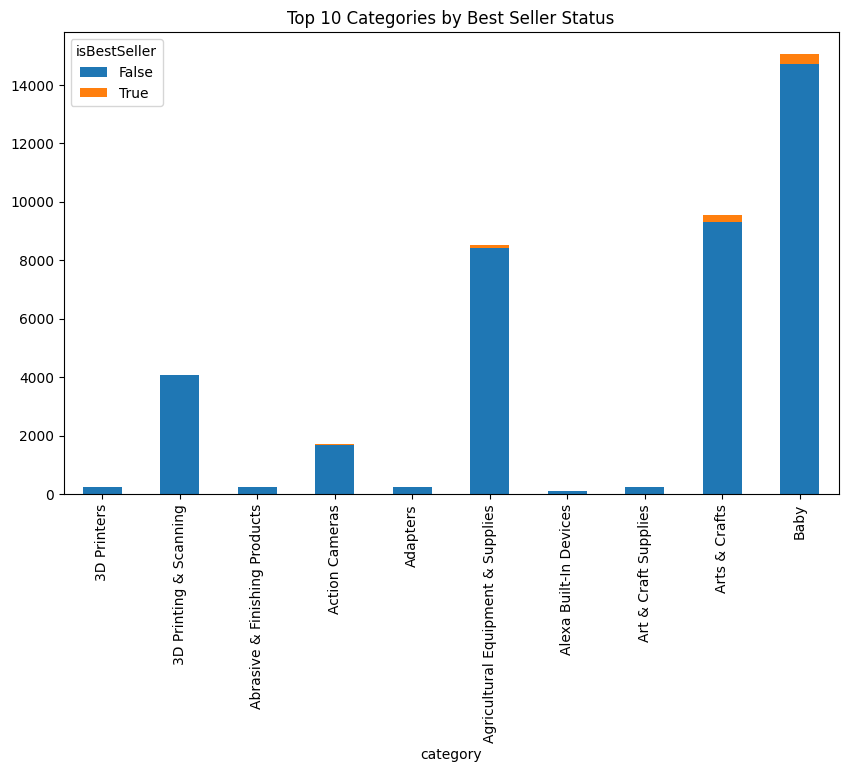

In [21]:
top_categories = (
    contingency_table
    .head(10)
)

top_categories.plot(
    kind='bar',
    stacked=True,
    figsize=(10,6),
    title="Top 10 Categories by Best Seller Status"
    )

#### **Part 2: Exploring Product Prices and Ratings Across Categories and Brands**

0. *Preliminary Step: Remove outliers in product prices.*

In [22]:
Q1 = amzn['price'].quantile(0.25)
Q3 = amzn['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

amzn_no_outliers = amzn[
    (amzn['price'] >= lower_bound) &
    (amzn['price'] <= upper_bound)
]

1. *Violin Plots*:
- Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.

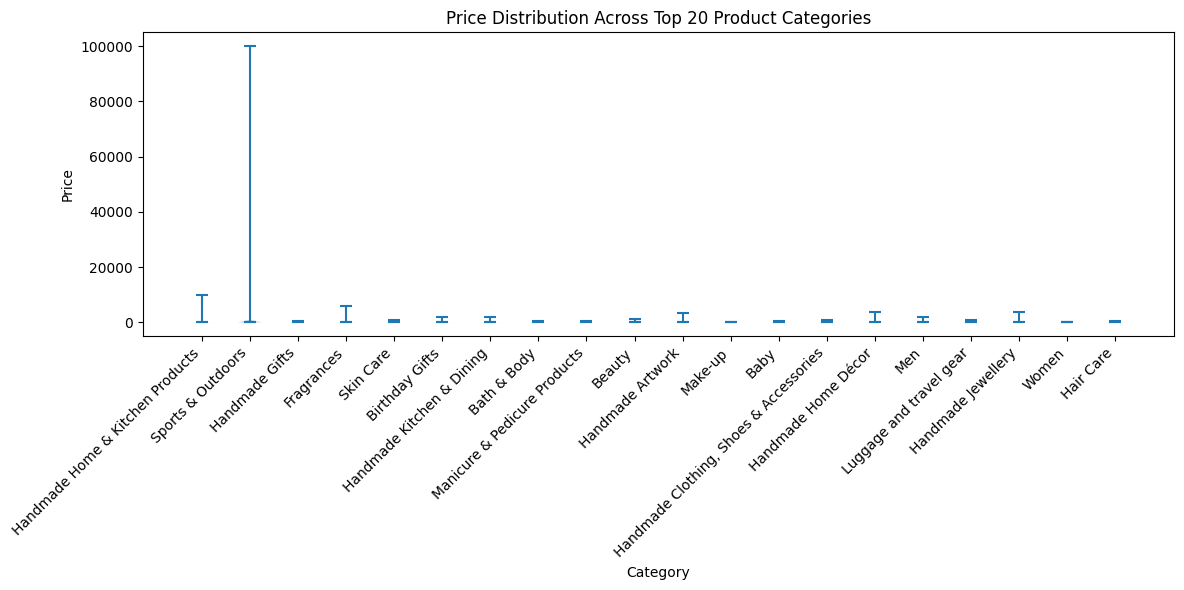

In [24]:
import matplotlib.pyplot as plt

# Keep top 20 categories by count
top_categories = (
    amzn['category']
    .value_counts()
    .head(20)
    .index
)

amzn_top = amzn[amzn['category'].isin(top_categories)]

categories = amzn_top['category'].unique()
price_data = [
    amzn_top[amzn_top['category'] == cat]['price']
    for cat in categories
]

plt.figure(figsize=(12, 6))
plt.violinplot(price_data, showmedians=True)

plt.xticks(range(1, len(categories) + 1), categories, rotation=45, ha='right')
plt.xlabel('Category')
plt.ylabel('Price')
plt.title('Price Distribution Across Top 20 Product Categories')
plt.tight_layout()
plt.show()

- Which product category tends to have the highest median price? Don't filter here by top categories.

In [25]:
median_prices = (
    amzn
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_prices.head(10)

category
Laptops                                1042.725
Desktop PCs                             810.400
Snowboards                              366.725
Home Audio Record Players               326.080
3D Printers                             319.000
Motorbike Exhaust & Exhaust Systems     313.830
Graphics Cards                          259.980
Snowboard Boots                         258.990
Lenses                                  249.990
Barebone PCs                            244.990
Name: price, dtype: float64

2. *Bar Charts*:
- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

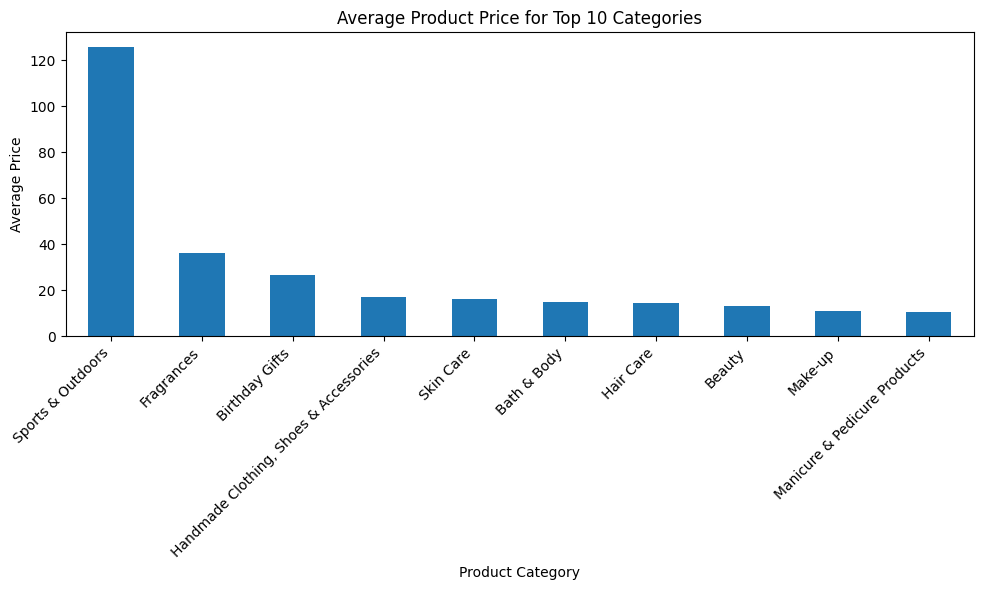

In [26]:
top_categories = (
    amzn['category']
    .value_counts()
    .head(10)
    .index
)

# Filter to top categories
amzn_top = amzn[amzn['category'].isin(top_categories)]

# Average price per category
avg_prices = (
    amzn_top
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

# Bar chart
plt.figure(figsize=(10, 6))
avg_prices.plot(kind='bar')

plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.title('Average Product Price for Top 10 Categories')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

- Which product category commands the highest average price? Don't filter here by top categories.

In [27]:
avg_prices = amzn.groupby('category')['price'].mean()

highest_avg_category = avg_prices.idxmax()
highest_avg_price = avg_prices.max()

print("Categoría con mayor precio promedio:", highest_avg_category)
print("Precio promedio:", highest_avg_price)

Categoría con mayor precio promedio: Laptops
Precio promedio: 1087.987826986755


3. *Box Plots*:
- Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

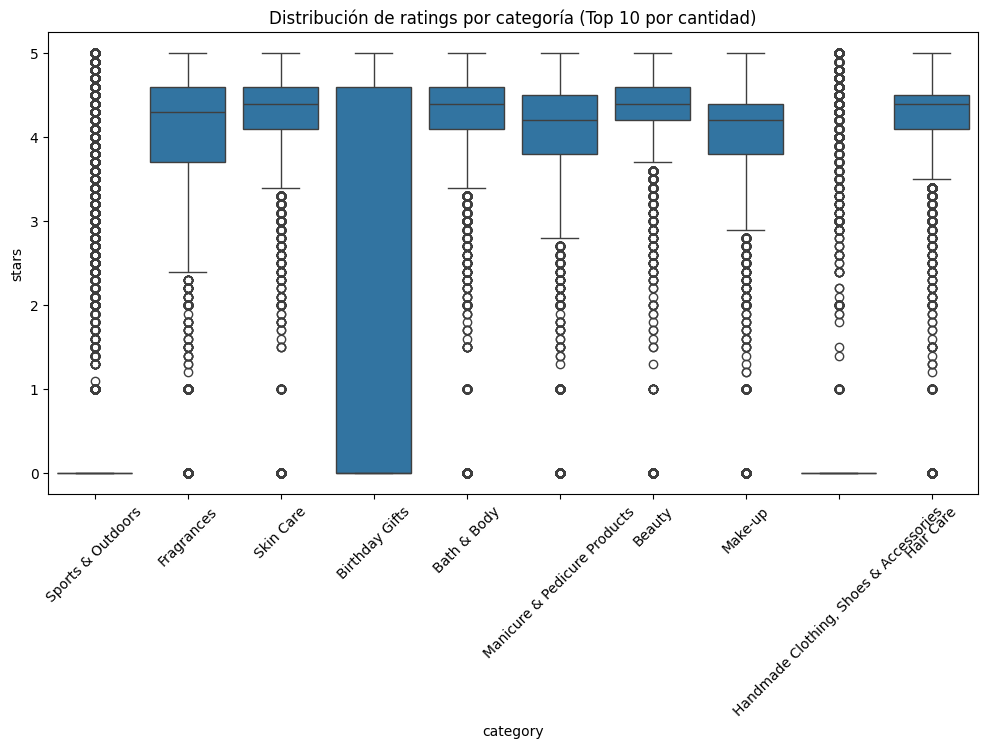

In [30]:
import seaborn as sns

top_categories = amzn['category'].value_counts().head(10).index

# Filtrar el DataFrame solo para esas categorías
filtered_amzn = amzn[amzn['category'].isin(top_categories)]

# Crear el boxplot de ratings por categoría
plt.figure(figsize=(12,6))
sns.boxplot(data=filtered_amzn, x='category', y='stars')
plt.xticks(rotation=45)
plt.title("Distribución de ratings por categoría (Top 10 por cantidad)")
plt.show()

- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [31]:
median_ratings = amzn.groupby('category')['stars'].median()

highest_median_category = median_ratings.idxmax()
highest_median_rating = median_ratings.max()

print("Categoría con mayor mediana de ratings:", highest_median_category)
print("Mediana de rating:", highest_median_rating)

Categoría con mayor mediana de ratings: Computer Memory
Mediana de rating: 4.7


#### **Part 3: Investigating the Interplay Between Product Prices and Ratings**
1. *Correlation Coefficients*:
- Calculate the correlation coefficient between `price` and `stars`.

In [32]:
correlation = amzn['price'].corr(amzn['stars'])

print("Coeficiente de correlación entre price y stars:", correlation)

Coeficiente de correlación entre price y stars: -0.12490673262148386


- Is there a significant correlation between product price and its rating?

In [34]:
from scipy.stats import pearsonr

clean_data = amzn[['price', 'stars']].dropna()

corr_coef, p_value = pearsonr(clean_data['price'], clean_data['stars'])

print("Coeficiente de correlación:", corr_coef)
print("Valor p:", p_value)

Coeficiente de correlación: -0.12490673262148598
Valor p: 0.0


2. *Visualizations*:
- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

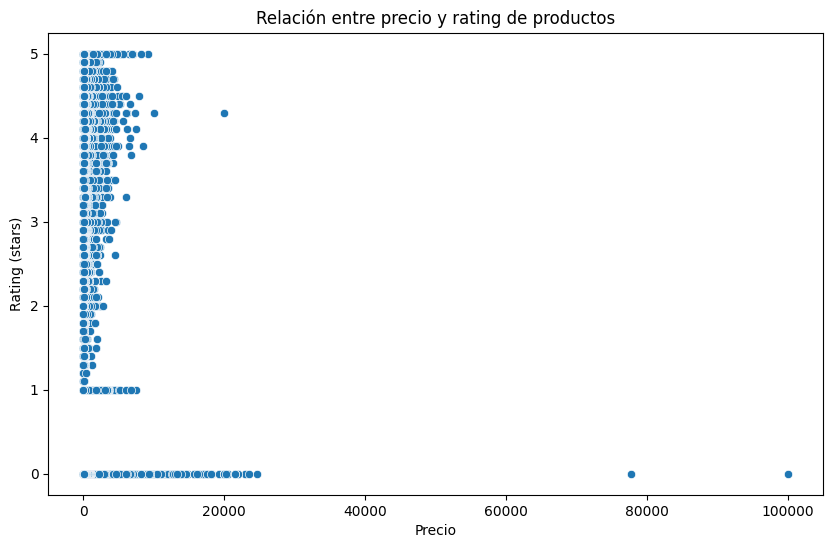

In [35]:
clean_data = amzn[['price', 'stars']].dropna()

plt.figure(figsize=(10,6))
sns.scatterplot(data=clean_data, x='price', y='stars')
plt.title("Relación entre precio y rating de productos")
plt.xlabel("Precio")
plt.ylabel("Rating (stars)")
plt.show()

- Use a correlation heatmap to visualize correlations between all numerical variables.

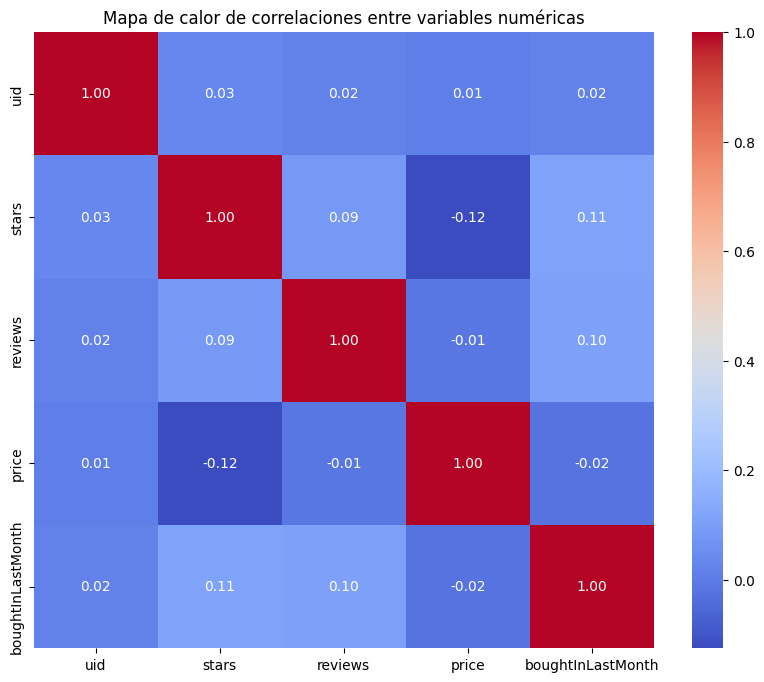

In [36]:
numeric_data = amzn.select_dtypes(include='number')

corr_matrix = numeric_data.corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Mapa de calor de correlaciones entre variables numéricas")
plt.show()

- Examine if product prices typically follow a normal distribution using a QQ plot. 

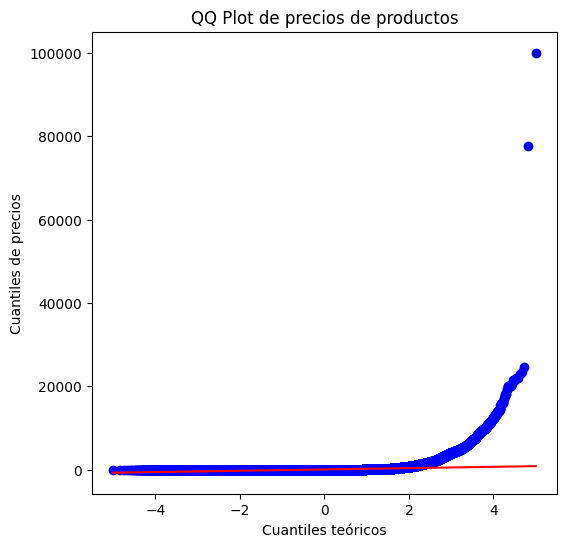

In [37]:
import scipy.stats as stats

# Eliminar valores nulos en price
prices = amzn['price'].dropna()

# Crear QQ plot
plt.figure(figsize=(6,6))
stats.probplot(prices, dist="norm", plot=plt)
plt.title("QQ Plot de precios de productos")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de precios")
plt.show()